# YouTube Spam Analysis

CSCI461 - Assignment 1

We analyze YouTube comments and classify them as Ham (0) or Spam (1).

Each row is one comment:
- CONTENT: original comment text.
- CLASS: target category, even though it uses numbers.
- VIDEO: video group.
- COMMENT_ID and AUTHOR: metadata.
- DATE: timestamp.

Logistic Regression is the main classifier.
Naive Bayes is the baseline for comparison.
K-Means explores groups without using CLASS during training.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import html
import json
from pathlib import Path
from IPython.display import display, Markdown
data_path = "../data/raw/"
output_dir = Path("../output")
figures_dir = output_dir / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

## 1. Load and understand the data

Read the five CSV files, add the video name, then merge them.
The paths assume that this notebook is inside notebook/.

In [2]:
psy = pd.read_csv(data_path + "Youtube01-Psy.csv")
katy = pd.read_csv(data_path + "Youtube02-KatyPerry.csv")
lmfao = pd.read_csv(data_path + "Youtube03-LMFAO.csv")
eminem = pd.read_csv(data_path + "Youtube04-Eminem.csv")
shakira = pd.read_csv(data_path + "Youtube05-Shakira.csv")
psy["VIDEO"] = "Psy"
katy["VIDEO"] = "KatyPerry"
lmfao["VIDEO"] = "LMFAO"
eminem["VIDEO"] = "Eminem"
shakira["VIDEO"] = "Shakira"
df = pd.concat([psy, katy, lmfao, eminem, shakira], ignore_index=True)
original_shape = df.shape
df.to_csv("../data/dataset.csv", index=False)

In [3]:
print("Original shape:", original_shape)
display(df.head())
print(df.columns.tolist())
display(df.dtypes)
df.info()
display(df.describe(include="all"))
display(df["CLASS"].value_counts())
display(df["VIDEO"].value_counts())

Original shape: (1956, 6)


,COMMENT_ID,AUTHOR,DATE,CONTENT,CLASS,VIDEO
0,LZQPQhLyRh80UYxNuaDWhIGQYNQ96IuCg-AYWqNPjpU,Julius NM,2013-11-07T06:20:48,"Huh, anyway check out this you[tube] channel: ...",1,Psy
1,LZQPQhLyRh_C2cTtd9MvFRJedxydaVW-2sNg5Diuo4A,adam riyati,2013-11-07T12:37:15,Hey guys check out my new channel and our firs...,1,Psy
2,LZQPQhLyRh9MSZYnf8djyk0gEF9BHDPYrrK-qCczIY8,Evgeny Murashkin,2013-11-08T17:34:21,just for test I have to say murdev.com,1,Psy
3,z13jhp0bxqncu512g22wvzkasxmvvzjaz04,ElNino Melendez,2013-11-09T08:28:43,me shaking my sexy ass on my channel enjoy ^_^ ﻿,1,Psy
4,z13fwbwp1oujthgqj04chlngpvzmtt3r3dw,GsMega,2013-11-10T16:05:38,watch?v=vtaRGgvGtWQ Check this out .﻿,1,Psy


['COMMENT_ID', 'AUTHOR', 'DATE', 'CONTENT', 'CLASS', 'VIDEO']


COMMENT_ID      str
AUTHOR          str
DATE            str
CONTENT         str
CLASS         int64
VIDEO           str
dtype: object

<class 'pandas.DataFrame'>
RangeIndex: 1956 entries, 0 to 1955
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   COMMENT_ID  1956 non-null   str  
 1   AUTHOR      1956 non-null   str  
 2   DATE        1711 non-null   str  
 3   CONTENT     1956 non-null   str  
 4   CLASS       1956 non-null   int64
 5   VIDEO       1956 non-null   str  
dtypes: int64(1), str(5)
memory usage: 424.7 KB


,COMMENT_ID,AUTHOR,DATE,CONTENT,CLASS,VIDEO
count,1956,1956,1711,1956,1956.000000,1956
unique,1953,1792,1709,1760,NaN,5
top,LneaDw26bFvPh9xBHNw1btQoyP60ay_WWthtvXCx37s,M.E.S,2014-11-07T19:33:46,Check out this video on YouTube:﻿,NaN,Eminem
freq,2,8,2,97,NaN,448
mean,NaN,NaN,NaN,NaN,0.513804,NaN
std,NaN,NaN,NaN,NaN,0.499937,NaN
min,NaN,NaN,NaN,NaN,0.000000,NaN
25%,NaN,NaN,NaN,NaN,0.000000,NaN
50%,NaN,NaN,NaN,NaN,1.000000,NaN
75%,NaN,NaN,NaN,NaN,1.000000,NaN


CLASS
1    1005
0     951
Name: count, dtype: int64

VIDEO
Eminem       448
LMFAO        438
Shakira      370
Psy          350
KatyPerry    350
Name: count, dtype: int64

## 2. Clean the data

Remove complete duplicate rows, but retain repeated text in distinct records.
Keep rows with missing DATE because our text models do not use dates.
Keep CONTENT unchanged and create a separate cleaned_text column.
Remove texts that become empty; this may discard emoji-only information.

In [4]:
display(df.isna().sum())
blank_texts = df["CONTENT"].fillna("").str.strip().eq("")
print("Missing or blank texts:", blank_texts.sum())
print("Full duplicates:", df.duplicated().sum())
print("Repeated texts:", df["CONTENT"].duplicated().sum())
display(df[df.duplicated(keep=False)].head(10))

COMMENT_ID      0
AUTHOR          0
DATE          245
CONTENT         0
CLASS           0
VIDEO           0
dtype: int64

Missing or blank texts: 0
Full duplicates: 3
Repeated texts: 196


,COMMENT_ID,AUTHOR,DATE,CONTENT,CLASS,VIDEO
1420,LneaDw26bFvPh9xBHNw1btQoyP60ay_WWthtvXCx37s,janez novak,NaN,share and like this page to win a hand signed ...,1,Eminem
1421,LneaDw26bFvPh9xBHNw1btQoyP60ay_WWthtvXCx37s,janez novak,NaN,share and like this page to win a hand signed ...,1,Eminem
1441,LneaDw26bFuH6iFsSrjlJLJIX3qD4R8-emuZ-aGUj0o,Amir bassem,NaN,if u love rihanna subscribe me,1,Eminem
1443,LneaDw26bFuH6iFsSrjlJLJIX3qD4R8-emuZ-aGUj0o,Amir bassem,NaN,if u love rihanna subscribe me,1,Eminem
1797,_2viQ_Qnc68fX3dYsfYuM-m4ELMJvxOQBmBOFHqGOk0,tyler sleetway,2013-10-05T00:57:25.078000,so beutiful,0,Shakira
1798,_2viQ_Qnc68fX3dYsfYuM-m4ELMJvxOQBmBOFHqGOk0,tyler sleetway,2013-10-05T00:57:25.078000,so beutiful,0,Shakira


In [5]:
df = df.drop_duplicates(keep="first", ignore_index=True)
print("Shape:", df.shape)
print("Full duplicates:", df.duplicated().sum())
print("Repeated texts:", df["CONTENT"].duplicated().sum())
display(df.isna().sum())
df["cleaned_text"] = df["CONTENT"].fillna("").apply(html.unescape)
df["cleaned_text"] = df["cleaned_text"].str.lower()
df["cleaned_text"] = df["cleaned_text"].str.replace(r"<[^>]+>", " ", regex=True)

Shape: (1953, 6)
Full duplicates: 0
Repeated texts: 193


COMMENT_ID      0
AUTHOR          0
DATE          243
CONTENT         0
CLASS           0
VIDEO           0
dtype: int64

In [6]:
df["cleaned_text"] = df["cleaned_text"].str.replace(
    r"https?://\S+|www\.\S+", " urltoken ", regex=True
)
df["cleaned_text"] = df["cleaned_text"].str.replace(r"\d+", " numbertoken ", regex=True)
df["cleaned_text"] = df["cleaned_text"].str.replace(r"[^\w\s]|_", " ", regex=True)
df["cleaned_text"] = df["cleaned_text"].str.replace(r"\s+", " ", regex=True).str.strip()
display(df[["CONTENT", "cleaned_text"]].head())

,CONTENT,cleaned_text
0,"Huh, anyway check out this you[tube] channel: ...",huh anyway check out this you tube channel kob...
1,Hey guys check out my new channel and our firs...,hey guys check out my new channel and our firs...
2,just for test I have to say murdev.com,just for test i have to say murdev com
3,me shaking my sexy ass on my channel enjoy ^_^ ﻿,me shaking my sexy ass on my channel enjoy
4,watch?v=vtaRGgvGtWQ Check this out .﻿,watch v vtarggvgtwq check this out


In [7]:
empty_cleaned = df["cleaned_text"].eq("")
print("Empty cleaned texts:", empty_cleaned.sum())
display(df.loc[empty_cleaned, ["CONTENT", "cleaned_text"]])
df = df.loc[~empty_cleaned].copy().reset_index(drop=True)
print("Before cleaning:", original_shape)
print("After cleaning:", df.shape)
print("Empty cleaned texts:", df["cleaned_text"].eq("").sum())

Empty cleaned texts: 8


,CONTENT,cleaned_text
134,❤️ ❤️ ❤️ ❤️ ❤️❤️❤️❤️﻿,
585,;-)﻿,
825,:)﻿,
1220,❤❤❤❤❤❤❤﻿,
1386,:)﻿,
1536,❤️❤️❤️﻿,
1818,:),
1822,:),


Before cleaning: (1956, 6)
After cleaning: (1945, 7)
Empty cleaned texts: 0


## 3. Features and transformations

Split cleaned text into tokens and create four numerical text features.
Character count includes spaces; average word length excludes spaces.
Map CLASS to readable names, convert dates, detect links and bin lengths.
Short = 1-5 words; Medium = 6-15; Long = 16 or more.
Missing dates become NaT. Original CONTENT and DATE remain unchanged.
Our URL pattern detects http/https/www links, not all bare domains.

In [8]:
df["tokens"] = df["cleaned_text"].str.split()
display(df[["cleaned_text", "tokens"]].head())
df["char_count"] = df["cleaned_text"].str.len()
df["word_count"] = df["tokens"].apply(len)
df["unique_word_count"] = df["tokens"].apply(lambda words: len(set(words)))
letters = df["cleaned_text"].str.replace(" ", "", regex=False).str.len()
df["avg_word_length"] = letters / df["word_count"]
feature_columns = ["char_count", "word_count", "unique_word_count", "avg_word_length"]
display(df[feature_columns].head())
display(df[feature_columns].describe())

,cleaned_text,tokens
0,huh anyway check out this you tube channel kob...,"[huh, anyway, check, out, this, you, tube, cha..."
1,hey guys check out my new channel and our firs...,"[hey, guys, check, out, my, new, channel, and,..."
2,just for test i have to say murdev com,"[just, for, test, i, have, to, say, murdev, com]"
3,me shaking my sexy ass on my channel enjoy,"[me, shaking, my, sexy, ass, on, my, channel, ..."
4,watch v vtarggvgtwq check this out,"[watch, v, vtarggvgtwq, check, this, out]"


,char_count,word_count,unique_word_count,avg_word_length
0,63,10,10,5.400000
1,157,32,28,3.937500
2,38,9,9,3.333333
3,42,9,8,3.777778
4,34,6,6,4.833333


,char_count,word_count,unique_word_count,avg_word_length
count,1945.000000,1945.000000,1945.000000,1945.000000
mean,83.461183,15.790746,13.022108,4.672405
std,119.317963,22.324416,15.624649,1.779905
min,1.000000,1.000000,1.000000,1.000000
25%,23.000000,4.000000,4.000000,3.896552
50%,40.000000,7.000000,7.000000,4.333333
75%,81.000000,16.000000,14.000000,5.000000
max,1584.000000,217.000000,123.000000,32.000000


In [9]:
df["class_name"] = df["CLASS"].map({0: "Ham", 1: "Spam"})
df["parsed_date"] = pd.to_datetime(df["DATE"], format="ISO8601", errors="coerce")
print("Missing converted dates:", df["parsed_date"].isna().sum())
df["has_url"] = df["CONTENT"].str.contains(
    r"https?://\S+|www\.\S+", case=False, regex=True, na=False
).astype(int)
df["length_group"] = pd.cut(
    df["word_count"], bins=[0, 5, 15, np.inf],
    labels=["Short", "Medium", "Long"], include_lowest=True
)
display(df["length_group"].value_counts(sort=False))

Missing converted dates: 243


length_group
Short     605
Medium    851
Long      489
Name: count, dtype: int64

## 4. Selection and sampling

loc selects by a condition; iloc selects by position; np.r_ combines ranges.
Random sampling selects individual records randomly.
Stratified sampling approximately preserves class proportions.
Cluster sampling selects two videos and keeps all their comments.
Its size and label proportions need not match a 20% individual sample.
These samples demonstrate sampling methods; they are not the model split.

In [10]:
display(df.loc[
    (df["CLASS"] == 1) & (df["has_url"] == 1),
    ["CONTENT", "CLASS", "VIDEO"]
].head())
display(df.iloc[0:5, 0:6])
display(df.iloc[np.r_[0:3, 10:13], 0:6])

,CONTENT,CLASS,VIDEO
12,https://twitter.com/GBphotographyGB﻿,1,Psy
14,please like :D https://premium.easypromosapp.c...,1,Psy
17,http://www.ebay.com/itm/171183229277?ssPageNam...,1,Psy
18,http://ubuntuone.com/40beUutVu2ZKxK4uTgPZ8K﻿,1,Psy
22,Show your AUBURN PRIDE HERE: http://www.teespr...,1,Psy


,COMMENT_ID,AUTHOR,DATE,CONTENT,CLASS,VIDEO
0,LZQPQhLyRh80UYxNuaDWhIGQYNQ96IuCg-AYWqNPjpU,Julius NM,2013-11-07T06:20:48,"Huh, anyway check out this you[tube] channel: ...",1,Psy
1,LZQPQhLyRh_C2cTtd9MvFRJedxydaVW-2sNg5Diuo4A,adam riyati,2013-11-07T12:37:15,Hey guys check out my new channel and our firs...,1,Psy
2,LZQPQhLyRh9MSZYnf8djyk0gEF9BHDPYrrK-qCczIY8,Evgeny Murashkin,2013-11-08T17:34:21,just for test I have to say murdev.com,1,Psy
3,z13jhp0bxqncu512g22wvzkasxmvvzjaz04,ElNino Melendez,2013-11-09T08:28:43,me shaking my sexy ass on my channel enjoy ^_^ ﻿,1,Psy
4,z13fwbwp1oujthgqj04chlngpvzmtt3r3dw,GsMega,2013-11-10T16:05:38,watch?v=vtaRGgvGtWQ Check this out .﻿,1,Psy


,COMMENT_ID,AUTHOR,DATE,CONTENT,CLASS,VIDEO
0,LZQPQhLyRh80UYxNuaDWhIGQYNQ96IuCg-AYWqNPjpU,Julius NM,2013-11-07T06:20:48,"Huh, anyway check out this you[tube] channel: ...",1,Psy
1,LZQPQhLyRh_C2cTtd9MvFRJedxydaVW-2sNg5Diuo4A,adam riyati,2013-11-07T12:37:15,Hey guys check out my new channel and our firs...,1,Psy
2,LZQPQhLyRh9MSZYnf8djyk0gEF9BHDPYrrK-qCczIY8,Evgeny Murashkin,2013-11-08T17:34:21,just for test I have to say murdev.com,1,Psy
10,z13auhww3oufjn1qo04ci3grqqjmfjexxuo0k,Huckyduck,2013-11-28T17:06:17,Hey subscribe to me﻿,1,Psy
11,z13xit5agm2zyh4f523rst2gowmbx5bml,Lone Twistt,2013-11-28T17:34:55,Once you have started reading do not stop. If...,1,Psy
12,z13pejoiuozwxtdu323dspopnri4xts0f,Archie Lewis,2013-11-28T17:54:39,https://twitter.com/GBphotographyGB﻿,1,Psy


In [11]:
from sklearn.model_selection import train_test_split
random_sample = df.sample(frac=0.20, random_state=42)
_, stratified_sample = train_test_split(
    df, test_size=0.20, stratify=df["CLASS"], random_state=42
)
rng = np.random.default_rng(42)
chosen_videos = rng.choice(sorted(df["VIDEO"].unique()), size=2, replace=False)
cluster_sample = df[df["VIDEO"].isin(chosen_videos)]
print("Selected videos:", chosen_videos)

Selected videos: ['Eminem' 'Psy']


In [12]:
samples = [df, random_sample, stratified_sample, cluster_sample]
distributions = [sample["class_name"].value_counts(normalize=True) for sample in samples]
sampling_comparison = pd.DataFrame(distributions, index=["Original", "Random", "Stratified", "Cluster"])
sampling_comparison = sampling_comparison.reindex(columns=["Ham", "Spam"], fill_value=0).fillna(0) * 100
sampling_comparison.columns = ["Ham %", "Spam %"]
sampling_comparison.insert(0, "Rows", [len(sample) for sample in samples])
sampling_comparison.index.name = "Method"
display(sampling_comparison.round(2))
sampling_comparison.to_csv(output_dir / "sampling_comparison.csv")

,Rows,Ham %,Spam %
Method,,,
Original,1945,48.43,51.57
Random,389,49.36,50.64
Stratified,389,48.33,51.67
Cluster,792,47.22,52.78


## 5. Correlation and text analysis

Compute correlations between the four numerical text features.
Character/word counts have strong positive correlation (about 0.988).
Word count/average word length have weak negative correlation (about -0.129).
Correlation does not establish causation; these features describe the same text.

Report all-token statistics first. Frequency views then exclude URL/number
markers and one-letter fragments, and compare before/after stopword removal.
Compare Ham/Spam mean lengths and top words. Frequency filters do not alter tokens.

,char_count,word_count,unique_word_count,avg_word_length
char_count,1.000,0.988,0.953,-0.069
word_count,0.988,1.000,0.970,-0.129
unique_word_count,0.953,0.970,1.000,-0.153
avg_word_length,-0.069,-0.129,-0.153,1.000


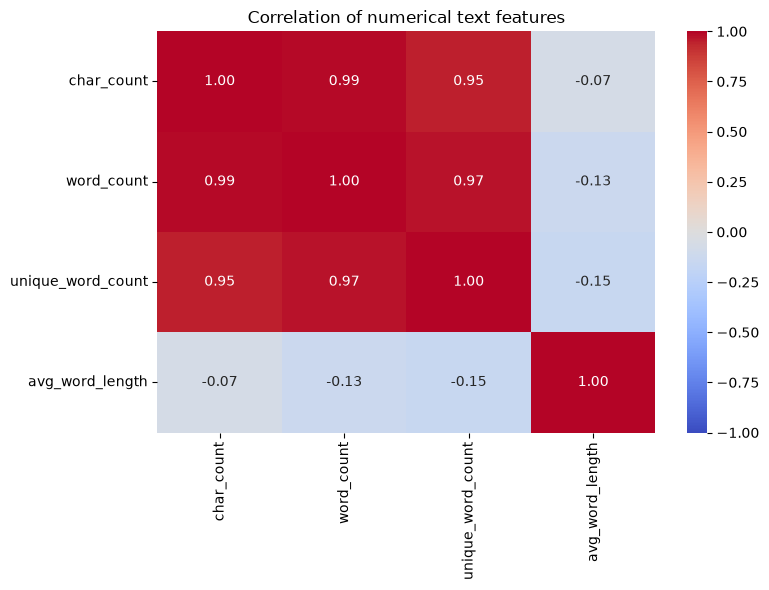

Characters vs words: 0.988
Words vs average word length: -0.129


In [13]:
corr = df[feature_columns].corr()
display(corr.round(3))
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation of numerical text features")
plt.tight_layout()
plt.savefig(figures_dir / "correlation_heatmap.png", dpi=150)
plt.show()
r_counts = corr.loc["char_count", "word_count"]
r_average = corr.loc["word_count", "avg_word_length"]
print("Characters vs words:", round(r_counts, 3))
print("Words vs average word length:", round(r_average, 3))

In [14]:
all_words = df["tokens"].explode()
print("Total tokens:", len(all_words))
print("Unique words:", all_words.nunique())
print("Average words per comment:", round(df["word_count"].mean(), 2))
top20_words = all_words.value_counts().head(20).reset_index()
top20_words.columns = ["word", "count"]
display(top20_words)

Total tokens: 30713
Unique words: 3645
Average words per comment: 15.79


,word,count
0,numbertoken,918
1,i,917
2,this,737
3,the,716
4,and,640
5,to,634
6,you,613
7,out,584
8,my,581
9,check,572


In [15]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
ignored_words = list(ENGLISH_STOP_WORDS) + ["urltoken", "numbertoken"]
words_for_frequency = all_words[~all_words.isin(["urltoken", "numbertoken"])]
words_for_frequency = words_for_frequency[words_for_frequency.str.len() > 1]
before_counts = words_for_frequency.value_counts()
before_top20 = before_counts.head(20).reset_index()
before_top20.columns = ["word", "count"]
display(before_top20)
filtered_words = words_for_frequency[~words_for_frequency.isin(ENGLISH_STOP_WORDS)]
after_counts = filtered_words.value_counts()
after_top20 = after_counts.head(20).reset_index()
after_top20.columns = ["word", "count"]
display(after_top20)

,word,count
0,this,737
1,the,716
2,and,640
3,to,634
4,you,613
5,out,584
6,my,581
7,check,572
8,on,389
9,it,385


,word,count
0,check,572
1,video,311
2,song,290
3,like,249
4,youtube,247
5,subscribe,229
6,channel,198
7,love,198
8,just,172
9,music,156


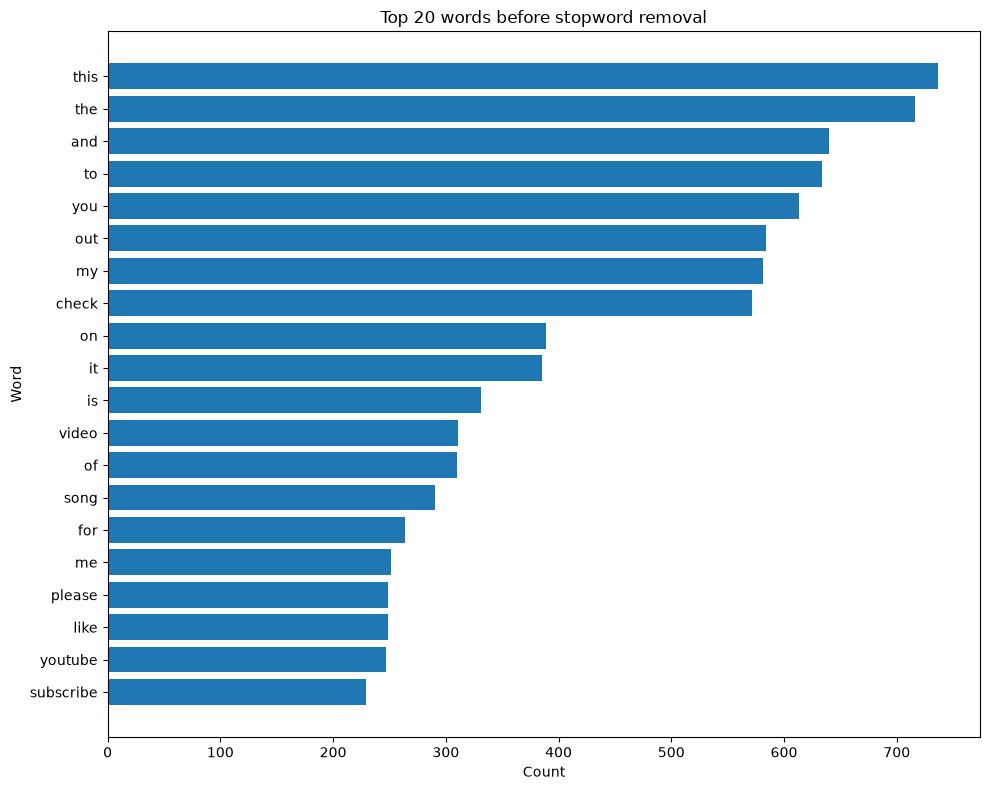

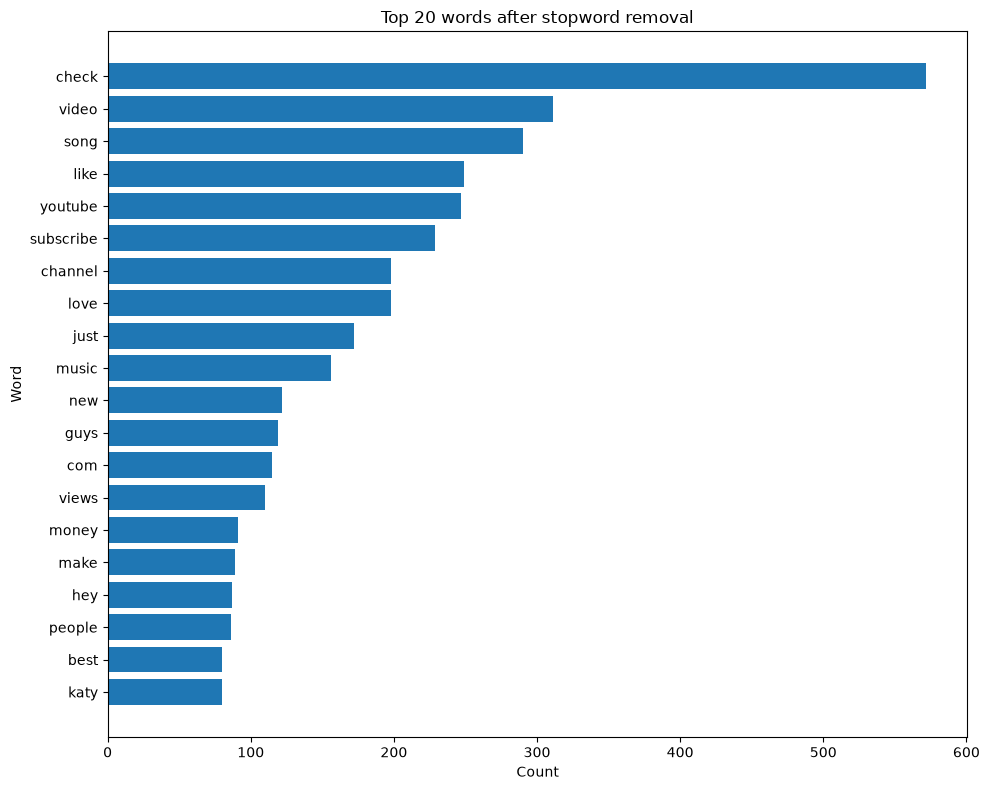

In [16]:
charts = [
    (before_top20, "before", "word_frequency_before_stopwords.png"),
    (after_top20, "after", "word_frequency_after_stopwords.png")
]
for table, stage, filename in charts:
    plt.figure(figsize=(10, 8))
    plt.barh(table["word"], table["count"])
    plt.gca().invert_yaxis()
    plt.xlabel("Count")
    plt.ylabel("Word")
    plt.title("Top 20 words " + stage + " stopword removal")
    plt.tight_layout()
    plt.savefig(figures_dir / filename, dpi=150)
    plt.show()

class_name
Spam    1003
Ham      942
Name: count, dtype: int64

,char_count,word_count
class_name,,
Ham,47.86,9.20
Spam,116.89,21.98


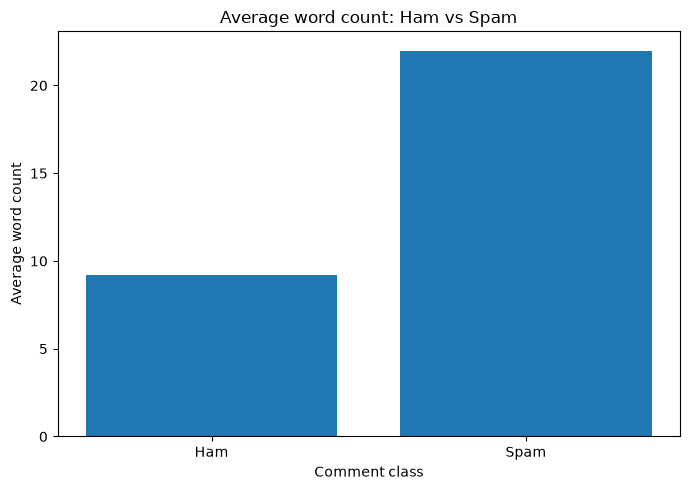

In [17]:
class_counts = df["class_name"].value_counts()
group_summary = df.groupby("class_name")[["char_count", "word_count"]].mean()
display(class_counts)
display(group_summary.round(2))
group_summary.to_csv(output_dir / "group_summary.csv")
plt.figure(figsize=(7, 5))
plt.bar(group_summary.index, group_summary["word_count"])
plt.xlabel("Comment class")
plt.ylabel("Average word count")
plt.title("Average word count: Ham vs Spam")
plt.tight_layout()
plt.savefig(figures_dir / "group_comparison.png", dpi=150)
plt.show()

In [18]:
tables = []
for name in ["Ham", "Spam"]:
    words = df.loc[df["class_name"] == name, "tokens"].explode()
    words = words[~words.isin(ignored_words)]
    words = words[words.str.len() > 1]
    top10 = words.value_counts().head(10).reset_index()
    top10.columns = ["word", "count"]
    top10.insert(0, "class_name", name)
    tables.append(top10)
    display(top10)
group_top10 = pd.concat(tables, ignore_index=True)
group_top10.to_csv(output_dir / "top10_words_by_class.csv", index=False)
url_rates = df.groupby("class_name")["has_url"].mean() * 100
display(url_rates.round(2))

,class_name,word,count
0,Ham,song,224
1,Ham,love,145
2,Ham,like,90
3,Ham,views,87
4,Ham,video,84
5,Ham,best,57
6,Ham,billion,56
7,Ham,katy,56
8,Ham,good,48
9,Ham,just,44


,class_name,word,count
0,Spam,check,559
1,Spam,subscribe,228
2,Spam,video,227
3,Spam,youtube,225
4,Spam,channel,197
5,Spam,like,159
6,Spam,just,128
7,Spam,new,119
8,Spam,music,117
9,Spam,guys,116


class_name
Ham      1.17
Spam    19.04
Name: has_url, dtype: float64

## Written Insights

1. **Class balance:** The cleaned dataset contains 942 Ham and 1,003 Spam comments.
   Both classes are well represented, so we should evaluate each class rather than rely on accuracy alone.

2. **Comment length:** Spam comments average 21.98 words, compared with 9.20 for Ham.
   Spam tends to be longer, but length alone cannot classify every comment.

3. **Vocabulary:** "song" occurs 224 times in Ham, while "check" occurs 559 times in Spam after filtering.
   This suggests music reactions in Ham and promotional requests in Spam. These are word occurrences, not counts of distinct comments.

4. **Stopwords:** Before stopword removal, "this" leads with 737 occurrences; afterwards, "check" leads with 572.
   Removing common grammatical words makes more descriptive vocabulary visible.

5. **Links:** Explicit links appear in 19.04% of Spam comments and 1.17% of Ham comments.
   Links may help distinguish the groups, but a link does not automatically mean Spam. Our pattern does not detect all bare domains.

## 6. Supervised text classification

CLASS is the true label: 0=Ham, 1=Spam.
Use the first StratifiedGroupKFold split: n_splits=5, shuffle=True, seed=42.
Identical cleaned texts stay together to prevent train/test overlap.
This is one holdout evaluation, not a five-fold average.
Class proportions are approximately preserved because complete groups stay together.
Learn TF-IDF from training text only; transform the test text with the same vectorizer.
Both models use the same split and features. Logistic Regression is primary.

In [19]:
from sklearn.model_selection import StratifiedGroupKFold
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_positions, test_positions = next(splitter.split(
    df["cleaned_text"], df["CLASS"], groups=df["cleaned_text"]
))
train_df = df.iloc[train_positions].copy()
test_df = df.iloc[test_positions].copy()
y_train = train_df["CLASS"]
y_test = test_df["CLASS"]
shared_texts = set(train_df["cleaned_text"]) & set(test_df["cleaned_text"])
assert len(shared_texts) == 0
label_counts = df.groupby("cleaned_text")["CLASS"].nunique()
conflicting_texts = int((label_counts > 1).sum())
print("Train / Test:", len(train_df), len(test_df))
print("Shared texts / conflicting labels:", len(shared_texts), conflicting_texts)

Train / Test: 1556 389
Shared texts / conflicting labels: 0 1


In [20]:
split_distribution = pd.DataFrame({
    "All %": df["CLASS"].value_counts(normalize=True) * 100,
    "Train %": y_train.value_counts(normalize=True) * 100,
    "Test %": y_test.value_counts(normalize=True) * 100
}).rename(index={0: "Ham", 1: "Spam"})
display(split_distribution.round(2))
from sklearn.feature_extraction.text import TfidfVectorizer
vectorizer = TfidfVectorizer(stop_words="english", max_features=5000)
X_train = vectorizer.fit_transform(train_df["cleaned_text"])
X_test = vectorizer.transform(test_df["cleaned_text"])
print(X_train.shape, X_test.shape)

,All %,Train %,Test %
CLASS,,,
Spam,51.57,51.54,51.67
Ham,48.43,48.46,48.33


(1556, 3097) (389, 3097)


In [21]:
from sklearn.naive_bayes import MultinomialNB
nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)
nb_pred = nb_model.predict(X_test)
from sklearn.linear_model import LogisticRegression
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train, y_train)
lr_pred = lr_model.predict(X_test)
main_model = lr_model
main_pred = lr_pred

In [22]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
nb_scores = [
    accuracy_score(y_test, nb_pred),
    precision_score(y_test, nb_pred, zero_division=0),
    recall_score(y_test, nb_pred, zero_division=0),
    f1_score(y_test, nb_pred, zero_division=0)
]
lr_scores = [
    accuracy_score(y_test, lr_pred),
    precision_score(y_test, lr_pred, zero_division=0),
    recall_score(y_test, lr_pred, zero_division=0),
    f1_score(y_test, lr_pred, zero_division=0)
]

In [23]:
nb_report = classification_report(
    y_test, nb_pred, labels=[0, 1], target_names=["Ham", "Spam"],
    digits=4, zero_division=0
)
print(nb_report)
lr_report = classification_report(
    y_test, lr_pred, labels=[0, 1], target_names=["Ham", "Spam"],
    digits=4, zero_division=0
)
print(lr_report)
metric_names = ["Accuracy", "Spam precision", "Spam recall", "Spam F1"]
comparison = pd.DataFrame([nb_scores, lr_scores], columns=metric_names)
comparison.insert(0, "Model", ["Naive Bayes", "Logistic Regression"])
display(comparison.round(4))
comparison.to_csv(output_dir / "model_comparison.csv", index=False)

              precision    recall  f1-score   support

         Ham     0.9688    0.8245    0.8908       188
        Spam     0.8559    0.9751    0.9116       201

    accuracy                         0.9023       389
   macro avg     0.9123    0.8998    0.9012       389
weighted avg     0.9104    0.9023    0.9016       389

              precision    recall  f1-score   support

         Ham     0.9628    0.9628    0.9628       188
        Spam     0.9652    0.9652    0.9652       201

    accuracy                         0.9640       389
   macro avg     0.9640    0.9640    0.9640       389
weighted avg     0.9640    0.9640    0.9640       389



,Model,Accuracy,Spam precision,Spam recall,Spam F1
0,Naive Bayes,0.9023,0.8559,0.9751,0.9116
1,Logistic Regression,0.9640,0.9652,0.9652,0.9652


## 7. Evaluate the models

Precision, recall and F1 in the comparison refer to Spam (class 1).
On the observed split, Logistic Regression improves accuracy, precision and F1.
Naive Bayes has slightly higher Spam recall: this is a tradeoff to acknowledge.
Confusion matrix rows are actual classes; columns are predicted: Ham, Spam.
Top-right = Ham incorrectly flagged as Spam; bottom-left = missed Spam.

These results describe one test split from five videos, not unseen videos.
Similar wording can remain across the split. Cleaning loses emoji/punctuation
signals, and English stopwords do not cover every language.

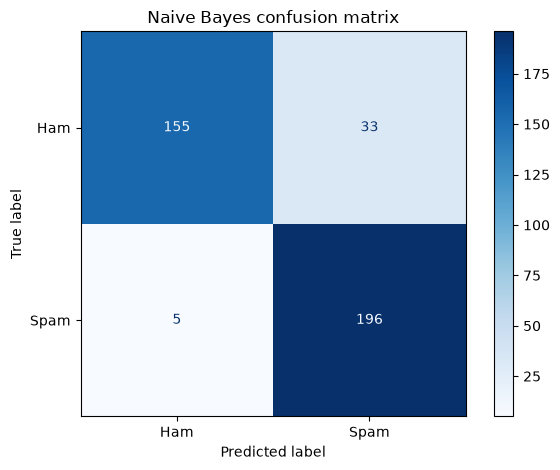

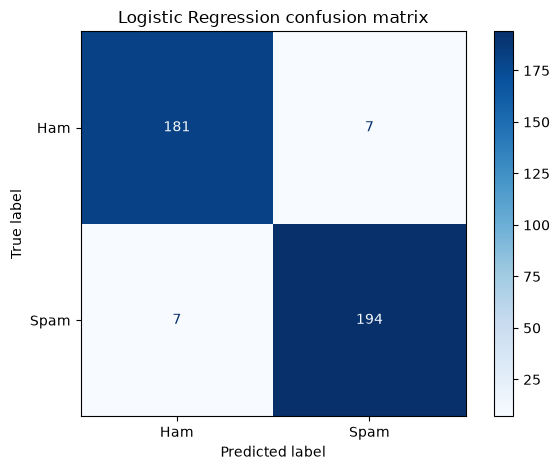

In [24]:
nb_cm = confusion_matrix(y_test, nb_pred, labels=[0, 1])
ConfusionMatrixDisplay(nb_cm, display_labels=["Ham", "Spam"]).plot(cmap="Blues", values_format="d")
plt.title("Naive Bayes confusion matrix")
plt.tight_layout()
plt.savefig(figures_dir / "naive_bayes_confusion_matrix.png", dpi=150)
plt.show()
lr_cm = confusion_matrix(y_test, main_pred, labels=[0, 1])
ConfusionMatrixDisplay(lr_cm, display_labels=["Ham", "Spam"]).plot(cmap="Blues", values_format="d")
plt.title("Logistic Regression confusion matrix")
plt.tight_layout()
plt.savefig(figures_dir / "confusion_matrix.png", dpi=150)
plt.show()

In [25]:
prediction_columns = ["COMMENT_ID", "CONTENT", "CLASS", "VIDEO"]
nb_predictions = test_df[prediction_columns].copy()
nb_predictions["predicted_class"] = nb_pred
nb_predictions.to_csv(output_dir / "naive_bayes_predictions.csv", index=False)
lr_predictions = test_df[prediction_columns].copy()
lr_predictions["predicted_class"] = main_pred
lr_predictions.to_csv(output_dir / "test_predictions.csv", index=False)
lr_errors = lr_predictions[lr_predictions["CLASS"] != lr_predictions["predicted_class"]]
print("Logistic Regression errors:", len(lr_errors))
display(lr_errors.head(10))
nb_tn, nb_fp, nb_fn, nb_tp = nb_cm.ravel()
lr_tn, lr_fp, lr_fn, lr_tp = lr_cm.ravel()

Logistic Regression errors: 14


,COMMENT_ID,CONTENT,CLASS,VIDEO,predicted_class
61,z12rc1ebfvrmufz5w04ccl2pmt3ih5dymq40k,The first comment is chuck norrus ovbiously :D﻿,0,Psy,1
81,z12jud4o3n34v5wph04ce3db0y2njn55gog0k,Admit it you just came here to check the numbe...,0,Psy,1
135,z12wsx5amr3ahbgl122mc5qr5v23vnist,"Dance dance,,,,,Psy http://www.reverbnation.c...",1,Psy,0
252,z133gjpr2ybqthyjt04cjjhrtwucsxw4tpk0k,I am now going to voyage to the first comment....,0,Psy,1
395,z135drnwswvsgvkyq04cfjh4xpb3cn2hugg,"She named the tiger Kitty Purry No, seriously...",0,KatyPerry,1
477,z13ighypdmuywprvc222crt42va2ctluz,She loves Vena. trojmiasto.pl/Vena-Bus-Taxi-o5...,1,KatyPerry,0
513,z12jj5kyfrjjhbq4e04cenuj1yyifhxq3hw,katy is beautiful. and this song is catchy. I'...,1,KatyPerry,0
548,z13myxsrskidhjt5u04cfb3hpqn4vb1q5ts0k,Every time I watch this mv I just so so so gla...,0,KatyPerry,1
595,z13xuxwywsewv3dvu23jgfig3um3ct5vv,:: ATTENTION : WE NEED 10 Million Views More f...,1,KatyPerry,0
807,z13uzb3zqoylw1kl022zidpqbn2tfpcjr04,I&#39;m A SUBSCRIBER﻿,1,LMFAO,0


In [26]:
majority_class = y_train.mode().iloc[0]
baseline_accuracy = (y_test == majority_class).mean()
with open(output_dir / "naive_bayes_metrics.txt", "w", encoding="utf-8") as report:
    print("Baseline: Naive Bayes; 0=Ham, 1=Spam", file=report)
    print(nb_report, "Confusion matrix (rows=actual; Ham, Spam):", nb_cm, sep="\n", file=report)
    print("False Spam alerts / missed Spam:", nb_fp, nb_fn, file=report)
with open(output_dir / "model_metrics.txt", "w", encoding="utf-8") as report:
    print("Primary model: Logistic Regression; max_iter=1000", file=report)
    print(lr_report, "Confusion matrix (rows=actual; Ham, Spam):", lr_cm, sep="\n", file=report)
    print("False Spam alerts / missed Spam:", lr_fp, lr_fn, file=report)
    print(comparison.round(4).to_string(index=False), file=report)
    print("Train / Test:", len(train_df), len(test_df), file=report)
    print("Shared texts / conflicting labels:", len(shared_texts), conflicting_texts, file=report)
    print("Majority-class baseline accuracy:", round(baseline_accuracy, 4), file=report)
    print("Class distributions (%):", split_distribution.round(2).to_string(), sep="\n", file=report)

## 8. K-Means clustering

Use independent TF-IDF; CLASS is not used in fitting or choosing k.
Exclude zero-vector rows from clustering only, and export their cluster as -1.
Try k=2,3,4,5 and select the highest silhouette among these candidates.
Near-zero silhouette indicates overlap; the best tested k is not a global optimum.
Repeated comments remain and contribute repeated weight.

Inspect top terms and sample comments. Vocabulary-based themes are preliminary.
Compare Ham/Spam percentages afterwards; cluster IDs do not equal class IDs.
A mixed label distribution alone does not establish a mixed topic.

In [27]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
cluster_vectorizer = TfidfVectorizer(
    stop_words=sorted(ignored_words), max_features=3000, min_df=2
)
all_cluster_vectors = cluster_vectorizer.fit_transform(df["cleaned_text"])
vector_totals = np.asarray(all_cluster_vectors.sum(axis=1)).ravel()
cluster_mask = vector_totals > 0
X_cluster = all_cluster_vectors[cluster_mask]
cluster_df = df.loc[cluster_mask].copy()
excluded_from_clustering = int((~cluster_mask).sum())
print("Used / excluded:", len(cluster_df), excluded_from_clustering)

Used / excluded: 1836 109


In [28]:
scores = []
models = {}
for k in [2, 3, 4, 5]:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_cluster)
    score = silhouette_score(X_cluster, labels, metric="euclidean")
    scores.append([k, score])
    models[k] = model
k_results = pd.DataFrame(scores, columns=["k", "silhouette"])
display(k_results.round(4))
k_results.to_csv(output_dir / "kmeans_k_comparison.csv", index=False)
best_row = k_results["silhouette"].idxmax()
best_k = int(k_results.loc[best_row, "k"])
best_silhouette = k_results.loc[best_row, "silhouette"]
best_kmeans = models[best_k]
print("Selected k:", best_k, "Silhouette:", round(best_silhouette, 4))

,k,silhouette
0,2,0.0536
1,3,0.0623
2,4,0.0699
3,5,0.0715


Selected k: 5 Silhouette: 0.0715


In [29]:
cluster_df["cluster"] = best_kmeans.labels_
df["cluster"] = -1
df.loc[cluster_df.index, "cluster"] = cluster_df["cluster"]
cluster_sizes = cluster_df["cluster"].value_counts().sort_index()
display(cluster_sizes.rename("Rows").to_frame())
cluster_labels_table = pd.crosstab(cluster_df["cluster"], cluster_df["class_name"])
cluster_labels_table = cluster_labels_table.reindex(columns=["Ham", "Spam"], fill_value=0)
cluster_label_percentages = cluster_labels_table.div(cluster_labels_table.sum(axis=1), axis=0) * 100
display(cluster_labels_table)
display(cluster_label_percentages.round(2))

,Rows
cluster,
0,1285
1,84
2,167
3,181
4,119


class_name,Ham,Spam
cluster,,
0,659,626
1,73,11
2,4,163
3,164,17
4,0,119


class_name,Ham,Spam
cluster,,
0,51.28,48.72
1,86.90,13.10
2,2.40,97.60
3,90.61,9.39
4,0.00,100.00


In [30]:
terms = cluster_vectorizer.get_feature_names_out()
cluster_terms = []
for number in range(best_k):
    positions = best_kmeans.cluster_centers_[number].argsort()[::-1][:10]
    cluster_terms.append(", ".join(terms[positions]))
cluster_details = cluster_sizes.rename("Rows").to_frame()
cluster_details["Top terms"] = cluster_terms
display(cluster_details)

,Rows,Top terms
cluster,,
0,1285,"like, check, channel, views, video, music, jus..."
1,84,"love, lie, shakira, perry, eminem, way, katy, ..."
2,167,"youtube, check, video, playlist, look, eminem,..."
3,181,"song, love, best, nice, good, old, like, favor..."
4,119,"subscribe, channel, like, videos, guys, ll, pl..."


In [31]:
promotional_terms = {"subscribe", "channel", "check", "money", "follow", "sub"}
music_terms = {"song", "music", "love", "beautiful", "amazing", "katy", "shakira", "eminem"}
cluster_details["Interpretation"] = "Mixed vocabulary; no clear topic"
for number in range(best_k):
    words = set(cluster_terms[number].split(", "))
    if words & promotional_terms:
        cluster_details.loc[number, "Interpretation"] = "Promotion-related vocabulary"
    elif words & music_terms:
        cluster_details.loc[number, "Interpretation"] = "Music/reaction vocabulary"
cluster_details["Ham %"] = cluster_label_percentages["Ham"].round(2)
cluster_details["Spam %"] = cluster_label_percentages["Spam"].round(2)
display(cluster_details)

,Rows,Top terms,Interpretation,Ham %,Spam %
cluster,,,,,
0,1285,"like, check, channel, views, video, music, jus...",Promotion-related vocabulary,51.28,48.72
1,84,"love, lie, shakira, perry, eminem, way, katy, ...",Music/reaction vocabulary,86.90,13.10
2,167,"youtube, check, video, playlist, look, eminem,...",Promotion-related vocabulary,2.40,97.60
3,181,"song, love, best, nice, good, old, like, favor...",Music/reaction vocabulary,90.61,9.39
4,119,"subscribe, channel, like, videos, guys, ll, pl...",Promotion-related vocabulary,0.00,100.00


In [32]:
example_tables = []
for number in range(best_k):
    members = cluster_df[cluster_df["cluster"] == number]
    examples = members.sample(n=min(3, len(members)), random_state=42)
    example_tables.append(examples[["cluster", "CONTENT", "cleaned_text"]])
cluster_examples = pd.concat(example_tables, ignore_index=True)
display(cluster_examples)

,cluster,CONTENT,cleaned_text
0,0,"Hey, hit this shit up while yall can, they kil...",hey hit this shit up while yall can they kille...
1,0,Hey plz check out my music video. Thanks!! :-)﻿,hey plz check out my music video thanks
2,0,Thumbs up if FE-FE-FE-FE-FEGELEIN brought u here﻿,thumbs up if fe fe fe fe fegelein brought u here
3,1,love!!!!﻿,love
4,1,i love this so much. AND also I Generate Free ...,i love this so much and also i generate free l...
5,1,I love﻿,i love
6,2,Check out this video on YouTube:﻿,check out this video on youtube
7,2,Check out this video on YouTube:﻿,check out this video on youtube
8,2,Check out this video on YouTube:﻿,check out this video on youtube
9,3,This looks so fun and it's a good song﻿,this looks so fun and it s a good song


In [33]:
with open(output_dir / "cluster_summary.txt", "w", encoding="utf-8") as report:
    print("K-Means; CLASS not used for fitting or choosing k.", file=report)
    print("Themes are preliminary; inspect examples. Cluster IDs are arbitrary.", file=report)
    print("Zero-vector rows have cluster=-1; repeated comments retain repeated weight.", file=report)
    print("Represented / excluded:", len(cluster_df), excluded_from_clustering, file=report)
    print("Selected k / silhouette:", best_k, best_silhouette, file=report)
    print("Candidate scores:", k_results.to_string(index=False), sep="\n", file=report)
    print("Cluster summaries:", cluster_details.to_string(), sep="\n", file=report)
    print("Class counts:", cluster_labels_table.to_string(), sep="\n", file=report)
    print("Examples:", cluster_examples.to_string(index=False), sep="\n", file=report)

## 9. Export and check outputs

Save all cleaned records, including the rows excluded only from clustering.
Serialize token lists as JSON strings so they can be recovered from the CSV.
All final results and figures are under output/.

In [34]:
export_df = df.copy()
export_df["tokens"] = export_df["tokens"].apply(lambda words: json.dumps(words, ensure_ascii=False))
export_df.to_csv(output_dir / "cleaned_data.csv", index=False, encoding="utf-8")
print("Saved rows:", len(export_df))

Saved rows: 1945


In [35]:
required_outputs = [
    "cleaned_data.csv", "model_metrics.txt", "naive_bayes_metrics.txt",
    "test_predictions.csv", "naive_bayes_predictions.csv", "model_comparison.csv",
    "cluster_summary.txt", "group_summary.csv",
    "top10_words_by_class.csv", "sampling_comparison.csv", "kmeans_k_comparison.csv"
]
required_figures = [
    "word_frequency_before_stopwords.png", "word_frequency_after_stopwords.png",
    "group_comparison.png", "correlation_heatmap.png", "confusion_matrix.png",
    "naive_bayes_confusion_matrix.png"
]

In [36]:
required_files = [output_dir / name for name in required_outputs]
required_files += [figures_dir / name for name in required_figures]
for file in required_files:
    print("OK" if file.is_file() else "MISSING", file.name)
assert all(file.is_file() for file in required_files)
assert df["cleaned_text"].str.strip().ne("").all()
assert np.isfinite(df[feature_columns].to_numpy()).all()
assert len(shared_texts) == 0
print("Notebook completed successfully")

OK cleaned_data.csv
OK model_metrics.txt
OK naive_bayes_metrics.txt
OK test_predictions.csv
OK naive_bayes_predictions.csv
OK model_comparison.csv
OK cluster_summary.txt
OK group_summary.csv
OK top10_words_by_class.csv
OK sampling_comparison.csv
OK kmeans_k_comparison.csv
OK word_frequency_before_stopwords.png
OK word_frequency_after_stopwords.png
OK group_comparison.png
OK correlation_heatmap.png
OK confusion_matrix.png
OK naive_bayes_confusion_matrix.png
Notebook completed successfully
